# Taller 10 — Modelo KNN (k vecinos más cercanos) · SOLUCIONARIO
**Minería de Datos**

**Profesor:** Guillermo Pinto Fuentes

## 1. Importación de librerías

Además de las herramientas habituales, se incorporan tres piezas que cambian la forma de evaluar el modelo:

- **`RepeatedStratifiedKFold` + `cross_val_score`**: los hiperparámetros (k y métrica de distancia) se eligen **solo con el conjunto de entrenamiento**. El conjunto de prueba queda reservado para una única evaluación final; usarlo para elegir k contamina la estimación del desempeño.
- **`make_pipeline`**: encadena escalamiento y modelo. Dentro de la validación cruzada, el `StandardScaler` se ajusta únicamente con los folds de entrenamiento de cada iteración, evitando que las estadísticas del fold de validación se filtren al modelo.
- **`SEMILLA`**: fija la aleatoriedad para que los resultados sean reproducibles.

In [1]:
# ============================================
# 1. Importación de librerías
# ============================================

import numpy as np
import pandas as pd

# Partición de datos, validación cruzada y escalamiento
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Modelo
from sklearn.neighbors import KNeighborsClassifier

# Métricas de evaluación
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Dataset multivariado incluido en sklearn (13 características químicas de vinos)
from sklearn.datasets import load_wine

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Semilla global para que todos los resultados sean reproducibles
SEMILLA = 42

### Funciones auxiliares

Las conclusiones del taller **no se escriben a mano**: se generan desde los resultados. Si cambia la semilla, la partición o el rango de k, los hallazgos se actualizan solos. Esto evita uno de los errores más comunes en un informe: una conclusión escrita que contradice la tabla que tiene justo encima.

La función `diferencia_concluyente()` aplica una regla heurística simple: una diferencia entre dos modelos solo se considera relevante si supera la variabilidad que ya existe entre folds.

In [2]:
# ============================================
# Funciones auxiliares (reutilizadas en todo el taller)
# ============================================

def hallazgo(texto):
    """Imprime una conclusión calculada a partir de los resultados (no texto fijo)."""
    print(f"🔎 HALLAZGO: {texto}")


def resumen_cv(puntajes):
    """Devuelve (media, desviación estándar) de los puntajes obtenidos en validación cruzada."""
    return puntajes.mean(), puntajes.std()


def diferencia_concluyente(media_a, media_b, desv_a, desv_b):
    """
    Regla heurística: la diferencia entre dos modelos se considera concluyente
    solo si supera la mayor de sus desviaciones estándar entre folds.
    """
    return abs(media_a - media_b) > max(desv_a, desv_b)

## 2. Carga del dataset

El dataset **Wine** contiene 178 vinos de tres cultivares, descritos por 13 mediciones químicas continuas. Se transforma a `DataFrame` para facilitar la exploración y se guardan los nombres de las clases para rotular reportes y matrices de confusión.

In [3]:
# ============================================
# 2. Cargar el dataset Wine de sklearn
# ============================================

wine = load_wine()

# Conversión a DataFrame: una columna por característica química
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Variable objetivo: cultivar del vino (0, 1, 2)
df["target"] = wine.target

# Nombres de las clases, útiles para rotular reportes y gráficos
nombres_clases = wine.target_names

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
# ✅ Verificación
assert df.shape == (178, 14), "El DataFrame debe tener 178 filas y 14 columnas (13 variables + target)."
print("✅ Dataset cargado correctamente.")

✅ Dataset cargado correctamente.


## 3. Análisis exploratorio

KNN clasifica una observación según la **distancia** a sus vecinos. Por eso, antes de modelar interesa revisar dos cosas:

1. **Las escalas de las variables**: si una variable se mide en cientos y otra en décimas, la primera dominará el cálculo de distancia.
2. **El balance de clases**: si las clases no tienen el mismo tamaño, la partición debe conservar sus proporciones (estratificación).

Se muestra el resumen estadístico transpuesto (una variable por fila) porque con 13 variables resulta más legible.

In [5]:
# ============================================
# 3. Análisis exploratorio: dimensiones, resumen y clases
# ============================================

print("Dimensiones del dataset:", df.shape)

print("\nResumen estadístico:")
display(df.describe().T)

print("\nDistribución de clases (proporción):")
proporciones = df["target"].value_counts(normalize=True).sort_index()
display(proporciones.round(3))

# --- Hallazgos dinámicos ---
# Contraste de escalas: desviación estándar de cada variable predictora
desv = df.drop(columns="target").std()
hallazgo(f"La variable de mayor dispersión ('{desv.idxmax()}', σ = {desv.max():.2f}) tiene una desviación "
         f"{desv.max() / desv.min():.0f} veces mayor que la de menor dispersión ('{desv.idxmin()}', σ = {desv.min():.3f}). "
         "En un modelo basado en distancias, esto anticipa la necesidad de escalar.")

hallazgo(f"La clase mayoritaria representa el {proporciones.max():.1%} de los datos y la minoritaria el "
         f"{proporciones.min():.1%}: conviene estratificar la partición para conservar estas proporciones.")

Dimensiones del dataset: (178, 14)

Resumen estadístico:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



Distribución de clases (proporción):


target
0    0.331
1    0.399
2    0.270
Name: proportion, dtype: float64

🔎 HALLAZGO: La variable de mayor dispersión ('proline', σ = 314.91) tiene una desviación 2530 veces mayor que la de menor dispersión ('nonflavanoid_phenols', σ = 0.124). En un modelo basado en distancias, esto anticipa la necesidad de escalar.
🔎 HALLAZGO: La clase mayoritaria representa el 39.9% de los datos y la minoritaria el 27.0%: conviene estratificar la partición para conservar estas proporciones.


## 4. Limpieza básica

KNN no admite valores nulos (no puede calcular distancias con datos faltantes) y los registros duplicados inflan artificialmente el peso de ciertos puntos al momento de votar entre vecinos.

In [6]:
# ============================================
# 4. Limpieza básica: nulos y duplicados
# ============================================

n_nulos = df.isnull().sum().sum()
n_duplicados = df.duplicated().sum()

print("Valores nulos (total):", n_nulos)
print("Registros duplicados:", n_duplicados)

# Eliminación de duplicados (si no existen, el DataFrame queda igual)
df = df.drop_duplicates()

hallazgo(f"Se encontraron {n_nulos} valores nulos y {n_duplicados} duplicados; "
         f"el dataset queda con {len(df)} registros para modelar.")

Valores nulos (total): 0
Registros duplicados: 0
🔎 HALLAZGO: Se encontraron 0 valores nulos y 0 duplicados; el dataset queda con 178 registros para modelar.


In [7]:
# ✅ Verificación
assert df.isnull().sum().sum() == 0 and df.duplicated().sum() == 0, "Aún quedan nulos o duplicados."
print("✅ Limpieza correcta.")

✅ Limpieza correcta.


## 5. Correlación entre características (Pearson)

En KNN todas las variables participan por igual en la distancia. Si dos variables están fuertemente correlacionadas, aportan información casi duplicada y esa dimensión queda **sobreponderada** en el cálculo.

La variable `target` se excluye del análisis: es categórica nominal (0, 1, 2) y su correlación de Pearson con las predictoras no tiene interpretación válida.

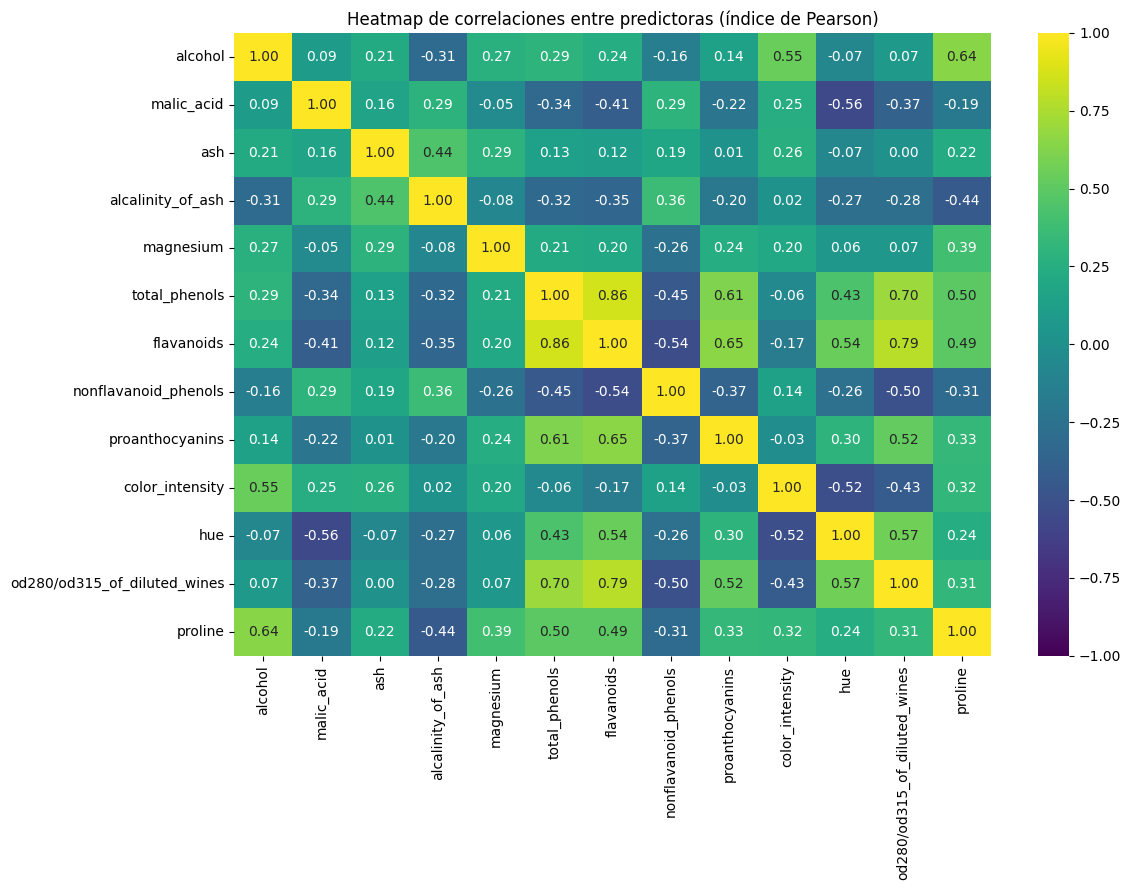

,,r de Pearson
total_phenols,flavanoids,0.865
flavanoids,od280/od315_of_diluted_wines,0.787


🔎 HALLAZGO: Se detectan 2 pares con |r| > 0.7; el más fuerte es 'total_phenols'–'flavanoids' (r = 0.86). En KNN, estas variables aportan información redundante a la distancia.


In [8]:
# ============================================
# 5. Correlación entre características (Pearson)
# ============================================

UMBRAL_R = 0.7  # umbral para considerar una correlación como fuerte

# Matriz de correlación solo entre predictoras (se excluye target)
corr_pearson = df.drop(columns="target").corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="viridis", vmin=-1, vmax=1)
plt.title("Heatmap de correlaciones entre predictoras (índice de Pearson)")
plt.tight_layout()
plt.show()

# Pares con correlación fuerte: se usa solo el triángulo superior para no repetir pares
mascara = np.triu(np.ones(corr_pearson.shape, dtype=bool), k=1)
pares = corr_pearson.where(mascara).stack()
fuertes = pares[pares.abs() > UMBRAL_R].sort_values(key=abs, ascending=False)
display(fuertes.round(3).to_frame("r de Pearson"))

if len(fuertes) > 0:
    v1, v2 = fuertes.index[0]
    hallazgo(f"Se detectan {len(fuertes)} pares con |r| > {UMBRAL_R}; el más fuerte es '{v1}'–'{v2}' "
             f"(r = {fuertes.iloc[0]:.2f}). En KNN, estas variables aportan información redundante a la distancia.")
else:
    hallazgo(f"No hay pares con |r| > {UMBRAL_R}: las variables aportan información relativamente independiente a la distancia.")

## 6. Separar características y etiqueta

`X` contiene las 13 mediciones químicas (predictoras) e `y` el cultivar (clase a predecir).

In [9]:
# ============================================
# 6. Separar características (X) y etiqueta (y)
# ============================================

X = df.drop(columns="target")
y = df["target"]

print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

Shape de X: (178, 13)
Shape de y: (178,)


In [10]:
# ✅ Verificación
assert X.shape == (178, 13) and "target" not in X.columns, "X debe tener 13 columnas y no incluir target."
assert y.shape == (178,), "y debe ser un vector de 178 elementos."
print("✅ X e y separados correctamente.")

✅ X e y separados correctamente.


## 7. División en entrenamiento y prueba

Se reserva el 25 % de los datos como **conjunto de prueba**. A partir de aquí, la regla es estricta: el conjunto de prueba **no se usa para tomar decisiones** (elegir k, elegir la métrica). Solo se usa para medir el modelo base de referencia y el modelo final.

La partición es **estratificada** porque, como mostró la exploración, las clases no tienen el mismo tamaño.

In [11]:
# ============================================
# 7. División en entrenamiento y prueba (estratificada)
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,        # 25 % para prueba
    random_state=SEMILLA,  # reproducibilidad
    stratify=y             # conserva las proporciones de clase en ambos conjuntos
)

print("Tamaño entrenamiento:", X_train.shape)
print("Tamaño prueba:", X_test.shape)

Tamaño entrenamiento: (133, 13)
Tamaño prueba: (45, 13)


In [12]:
# ✅ Verificación
assert X_train.shape == (133, 13) and X_test.shape == (45, 13), "Revisa test_size."
assert np.allclose(y_train.value_counts(normalize=True).sort_index(),
                   y_test.value_counts(normalize=True).sort_index(), atol=0.03), "Revisa stratify."
print("✅ Partición estratificada correcta.")

✅ Partición estratificada correcta.


## 8. Esquema de validación cruzada

Con solo 133 observaciones de entrenamiento, una única partición en folds puede dar resultados muy distintos según qué observaciones caigan en cada fold. Por eso se usa **validación cruzada estratificada repetida**: 5 folds × 5 repeticiones = 25 estimaciones por modelo. La media resume el desempeño esperado y la desviación estándar indica cuánto confiar en él.

Este mismo objeto `cv` se reutiliza en todas las comparaciones, de modo que todos los modelos se evalúan sobre exactamente las mismas particiones.

In [13]:
# ============================================
# 8. Esquema de validación cruzada (solo sobre entrenamiento)
# ============================================

cv = RepeatedStratifiedKFold(
    n_splits=5,            # 5 folds: cada fold de validación tiene ~27 observaciones
    n_repeats=5,           # 5 repeticiones con distinta asignación a folds
    random_state=SEMILLA
)

print(f"Cada modelo se evaluará {cv.get_n_splits()} veces.")

Cada modelo se evaluará 25 veces.


## 9. 🧩 Reto: ¿por qué escalar en KNN?

### 9.1 ¿Qué variable domina la distancia sin escalar?

Para dos observaciones tomadas al azar, la diferencia esperada al cuadrado en una variable es proporcional a su varianza: $E[(x_i - x_j)^2] = 2\,\mathrm{Var}(X)$. Como la distancia euclidiana al cuadrado es la suma de esas diferencias, **la proporción de varianza de cada variable aproxima su peso en la distancia**.

Se calcula sobre `X_train` (sin escalar) para ver qué tan desbalanceado es ese peso.

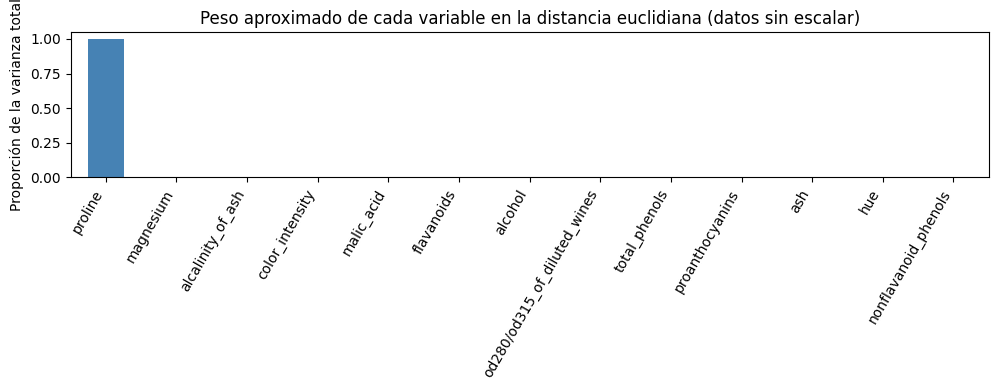

🔎 HALLAZGO: Sin escalar, 'proline' concentra el 99.7% de la distancia euclidiana esperada; las otras 12 variables suman apenas 0.3%. En la práctica, el modelo clasificaría usando casi una sola variable.


In [14]:
# ============================================
# 9.1 Aporte de cada variable a la distancia euclidiana (sin escalar)
# ============================================

# Varianza de cada variable en entrenamiento
varianzas = X_train.var()

# Proporción de la varianza total: peso aproximado de cada variable en la distancia
aporte = (varianzas / varianzas.sum()).sort_values(ascending=False)

plt.figure(figsize=(10, 4))
aporte.plot(kind="bar", color="steelblue")
plt.title("Peso aproximado de cada variable en la distancia euclidiana (datos sin escalar)")
plt.ylabel("Proporción de la varianza total")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

hallazgo(f"Sin escalar, '{aporte.index[0]}' concentra el {aporte.iloc[0]:.1%} de la distancia euclidiana esperada; "
         f"las otras {len(aporte) - 1} variables suman apenas {aporte.iloc[1:].sum():.1%}. "
         "En la práctica, el modelo clasificaría usando casi una sola variable.")

### 9.2 Desempeño con y sin escalamiento

Se comparan dos versiones de KNN con k = 5 usando la misma validación cruzada:

- **Sin escalar**: el modelo recibe las variables en sus unidades originales.
- **Con escalamiento**: se usa `make_pipeline(StandardScaler(), KNeighborsClassifier())`. En cada iteración, el escalador se ajusta solo con los folds de entrenamiento y se aplica al fold de validación, que es exactamente lo que ocurrirá con datos nuevos.

In [15]:
# ============================================
# 9.2 KNN sin escalar vs. KNN escalado (validación cruzada)
# ============================================

# Modelo sin escalar: recibe X_train en unidades originales
knn_sin_escalar = KNeighborsClassifier(n_neighbors=5)

# Modelo escalado: el pipeline ajusta el StandardScaler dentro de cada fold
knn_escalado = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# Ambos se evalúan sobre las mismas particiones (mismo objeto cv)
puntajes_sin = cross_val_score(knn_sin_escalar, X_train, y_train, cv=cv, scoring="accuracy")
puntajes_con = cross_val_score(knn_escalado, X_train, y_train, cv=cv, scoring="accuracy")

m_sin, s_sin = resumen_cv(puntajes_sin)
m_con, s_con = resumen_cv(puntajes_con)

comparacion_escala = pd.DataFrame(
    {"Accuracy media": [m_sin, m_con], "Desv. estándar": [s_sin, s_con]},
    index=["Sin escalar", "Con StandardScaler"]
)
display(comparacion_escala.round(3))

escala_concluyente = diferencia_concluyente(m_con, m_sin, s_con, s_sin)
hallazgo(f"Escalar cambia el accuracy medio de {m_sin:.3f} a {m_con:.3f} (Δ = {m_con - m_sin:+.3f}). "
         f"La diferencia {'ES' if escala_concluyente else 'NO es'} concluyente respecto de la variabilidad entre folds.")

,Accuracy media,Desv. estándar
Sin escalar,0.695,0.068
Con StandardScaler,0.956,0.029


🔎 HALLAZGO: Escalar cambia el accuracy medio de 0.695 a 0.956 (Δ = +0.262). La diferencia ES concluyente respecto de la variabilidad entre folds.


In [16]:
# ✅ Verificación
assert len(puntajes_sin) == 25 and len(puntajes_con) == 25, "Cada modelo debe tener 25 puntajes (5 folds × 5 repeticiones)."
assert m_con > m_sin, "El modelo escalado debería superar al modelo sin escalar: revisa el pipeline."
print("✅ Reto de escalamiento resuelto.")

✅ Reto de escalamiento resuelto.


## 10. Escalamiento del modelo base

Para el modelo base se aplica el escalamiento de forma explícita (sin pipeline), para hacer visible la regla central: el `StandardScaler` se **ajusta solo con entrenamiento** (`fit_transform`) y el conjunto de prueba se **transforma con esos mismos parámetros** (`transform`). Ajustarlo con prueba equivaldría a usar información que en producción no existe.

In [17]:
# ============================================
# 10. Escalamiento (StandardScaler)
# ============================================

scaler = StandardScaler()

# Ajuste (media y desviación) y transformación con datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Prueba: solo se transforma, reutilizando la media y desviación de entrenamiento
X_test_scaled = scaler.transform(X_test)

print("Ejemplo de valores escalados (primeras filas de entrenamiento):")
pd.DataFrame(X_train_scaled, columns=X.columns).head()

Ejemplo de valores escalados (primeras filas de entrenamiento):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,2.330418,-0.637963,-0.744271,-1.700059,-0.200993,0.824559,1.033603,-0.604880,0.643169,0.081545,0.578875,0.373857,0.979713
1,-0.573640,-0.555102,-1.459394,0.238093,-1.004966,-0.131417,-0.076878,-0.350830,-0.213445,-0.877403,0.401109,1.428364,-0.248245
2,0.390207,-0.637963,1.777478,-1.252793,0.669977,0.505900,0.719316,-0.181464,-0.419032,-0.173043,0.623317,0.271335,0.436514
3,-0.798955,-1.236399,-1.572309,-1.461517,2.411918,-0.609404,-0.150212,-0.096781,1.979486,-0.682219,0.489992,-0.417024,0.008540
4,0.239997,0.024920,1.137631,-0.328443,0.066998,0.824559,1.305985,-0.520197,2.065147,0.285215,0.356668,0.842526,1.440608


In [18]:
# ✅ Verificación
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-8), "Entrenamiento escalado debe tener media 0."
assert not np.allclose(X_test_scaled.mean(axis=0), 0, atol=1e-8), "Prueba no debe ajustarse con su propia media: usa transform()."
print("✅ Escalamiento aplicado sin fuga de información.")

✅ Escalamiento aplicado sin fuga de información.


## 11. Entrenamiento del modelo base (k = 5)

Se entrena un KNN con k = 5 como **referencia**. Este valor no se eligió con ningún criterio; es un punto de partida contra el cual comparar el modelo ajustado.

En KNN, `fit()` no estima parámetros: solo almacena los datos de entrenamiento. El trabajo real ocurre en `predict()`, cuando se calculan las distancias a todos los puntos almacenados.

In [19]:
# ============================================
# 11. Entrenamiento del modelo base KNN (k = 5)
# ============================================

knn_base = KNeighborsClassifier(n_neighbors=5)

# fit() en KNN solo memoriza los datos escalados de entrenamiento
knn_base.fit(X_train_scaled, y_train)

print("Modelo base entrenado correctamente.")

Modelo base entrenado correctamente.


## 12. Evaluación del modelo base

Se mide el modelo base sobre el conjunto de prueba. Este resultado es **solo una referencia**: no se usará para elegir k ni la métrica de distancia.

Al interpretar, considera el tamaño del conjunto de prueba: con 45 observaciones, cada error equivale a más de 2 puntos porcentuales de accuracy.

Accuracy (prueba): 0.933

Reporte de clasificación:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45



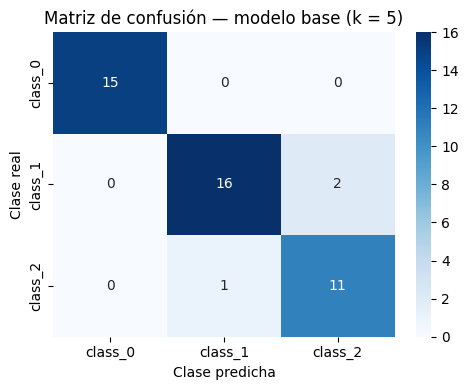

🔎 HALLAZGO: El modelo base comete 3 errores; el más frecuente es clasificar 'class_1' como 'class_2' (2 casos). Cada error equivale a 2.2% de accuracy.


In [20]:
# ============================================
# 12. Evaluación del modelo base (conjunto de prueba)
# ============================================

y_pred_base = knn_base.predict(X_test_scaled)
acc_base = accuracy_score(y_test, y_pred_base)

print(f"Accuracy (prueba): {acc_base:.3f}")
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_base, target_names=nombres_clases))

# Matriz de confusión rotulada con los nombres de clase
cm_base = confusion_matrix(y_test, y_pred_base)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_base, annot=True, fmt="d", cmap="Blues",
            xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión — modelo base (k = 5)")
plt.tight_layout()
plt.show()

# Hallazgo: error más frecuente (máximo fuera de la diagonal)
errores_cm = cm_base.copy()
np.fill_diagonal(errores_cm, 0)
if errores_cm.sum() == 0:
    hallazgo("El modelo base no comete errores en el conjunto de prueba.")
else:
    i, j = np.unravel_index(errores_cm.argmax(), errores_cm.shape)
    hallazgo(f"El modelo base comete {errores_cm.sum()} errores; el más frecuente es clasificar "
             f"'{nombres_clases[i]}' como '{nombres_clases[j]}' ({errores_cm[i, j]} casos). "
             f"Cada error equivale a {1 / len(y_test):.1%} de accuracy.")

## 13. Selección de k con validación cruzada

k controla el equilibrio entre sesgo y varianza:

- **k pequeño**: la frontera de decisión se ajusta a cada punto; el modelo es sensible al ruido (alta varianza).
- **k grande**: la votación promedia sobre muchos vecinos; la frontera se suaviza y puede ignorar patrones locales (alto sesgo).

Se evalúan los valores de k entre 1 y 20 **solo con entrenamiento**, mediante el pipeline y el esquema `cv`. La banda sombreada del gráfico (± 1 desviación estándar) permite juzgar si las diferencias entre valores de k son reales o están dentro del ruido.

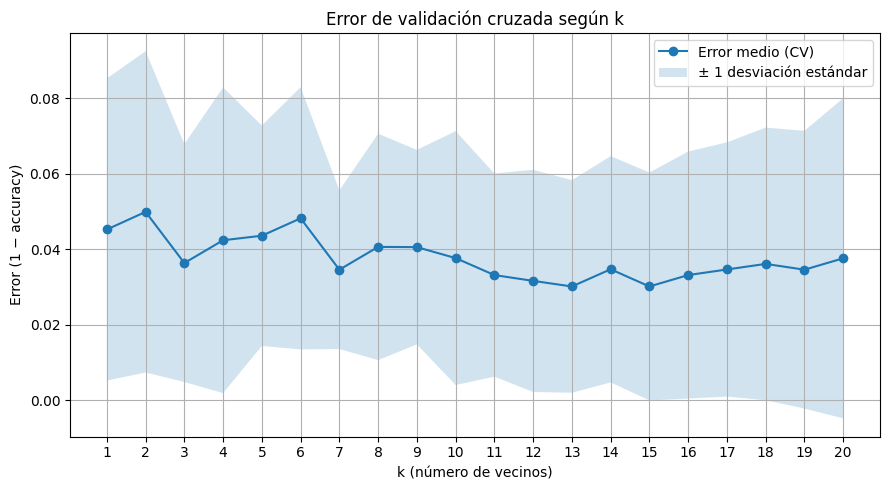

🔎 HALLAZGO: El mejor k según validación cruzada es 13 (accuracy media = 0.970 ± 0.028).
🔎 HALLAZGO: La diferencia entre el mejor y el peor k (0.020) es menor que la desviación típica entre folds (0.033): la curva es prácticamente plana y varios valores de k son equivalentes en la práctica.


In [21]:
# ============================================
# 13. Selección de k mediante validación cruzada
# ============================================

valores_k = range(1, 21)
resultados_k = []

for k in valores_k:
    # Pipeline: el escalamiento se ajusta dentro de cada fold
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    puntajes = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy")
    media, desv_k = resumen_cv(puntajes)
    resultados_k.append({"k": k, "accuracy_media": media, "desv": desv_k})

resultados_k = pd.DataFrame(resultados_k).set_index("k")
resultados_k["error_medio"] = 1 - resultados_k["accuracy_media"]

# Curva de error con banda de ± 1 desviación estándar
plt.figure(figsize=(9, 5))
plt.plot(resultados_k.index, resultados_k["error_medio"], marker="o", label="Error medio (CV)")
plt.fill_between(resultados_k.index,
                 resultados_k["error_medio"] - resultados_k["desv"],
                 resultados_k["error_medio"] + resultados_k["desv"],
                 alpha=0.2, label="± 1 desviación estándar")
plt.title("Error de validación cruzada según k")
plt.xlabel("k (número de vecinos)")
plt.ylabel("Error (1 − accuracy)")
plt.xticks(list(valores_k))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# --- Hallazgos dinámicos ---
mejor_k = int(resultados_k["accuracy_media"].idxmax())
acc_mejor_k = resultados_k.loc[mejor_k, "accuracy_media"]
desv_mejor_k = resultados_k.loc[mejor_k, "desv"]
rango_acc = resultados_k["accuracy_media"].max() - resultados_k["accuracy_media"].min()
desv_tipica = resultados_k["desv"].mean()

hallazgo(f"El mejor k según validación cruzada es {mejor_k} (accuracy media = {acc_mejor_k:.3f} ± {desv_mejor_k:.3f}).")
if rango_acc < desv_tipica:
    hallazgo(f"La diferencia entre el mejor y el peor k ({rango_acc:.3f}) es menor que la desviación típica entre folds "
             f"({desv_tipica:.3f}): la curva es prácticamente plana y varios valores de k son equivalentes en la práctica.")
else:
    hallazgo(f"La diferencia entre el mejor y el peor k ({rango_acc:.3f}) supera la desviación típica entre folds "
             f"({desv_tipica:.3f}): la elección de k sí tiene impacto en el desempeño.")

In [22]:
# ✅ Verificación
assert len(resultados_k) == 20, "Deben evaluarse los 20 valores de k."
assert 1 <= mejor_k <= 20, "mejor_k debe estar entre 1 y 20."
print(f"✅ Selección de k completada (mejor_k = {mejor_k}).")

✅ Selección de k completada (mejor_k = 13).


## 14. Comparación de métricas de distancia

Todas las métricas son casos de la distancia de Minkowski, $d_p(a,b) = \left(\sum_i |a_i - b_i|^p\right)^{1/p}$, y se diferencian en cómo agregan las diferencias por variable:

| Métrica | p | Cómo agrega las diferencias |
|---|---|---|
| Manhattan | 1 | Suma de diferencias absolutas: cada variable aporta en proporción lineal; una sola diferencia grande pesa menos que en Euclidean. |
| Euclidean | 2 | Penaliza cuadráticamente: las diferencias grandes en una variable pesan más. |
| Minkowski p = 3 | 3 | Acentúa aún más las diferencias grandes. |
| Chebyshev | ∞ | Solo considera la **mayor** diferencia entre variables; descarta la información de las demás dimensiones. |

Ninguna métrica es mejor a priori: depende de la estructura de los datos. Por eso se comparan con validación cruzada, usando el `mejor_k` obtenido en la sección anterior, y se verifica si las diferencias superan la variabilidad entre folds.

Accuracy por métrica (validación cruzada, k = 13):


,accuracy_media,desv
metrica,,
euclidean,0.970,0.028
manhattan,0.968,0.029
minkowski_p3,0.950,0.040
chebyshev,0.934,0.052


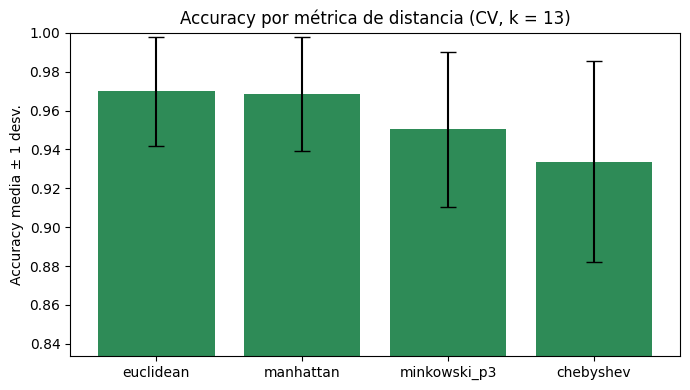

🔎 HALLAZGO: La métrica con mayor accuracy medio es 'euclidean' (0.970); la de menor desempeño es 'chebyshev' (0.934).
🔎 HALLAZGO: La ventaja de 'euclidean' sobre 'manhattan' NO es concluyente respecto de la variabilidad entre folds: ambas métricas son equivalentes en la práctica para este dataset.


In [23]:
# ============================================
# 14. Comparación de métricas de distancia (validación cruzada)
# ============================================

# Cada métrica se define con sus parámetros para KNeighborsClassifier
metricas = {
    "euclidean":    {"metric": "euclidean"},
    "manhattan":    {"metric": "manhattan"},
    "chebyshev":    {"metric": "chebyshev"},
    "minkowski_p3": {"metric": "minkowski", "p": 3},
}

resultados_metricas = []

for nombre, params in metricas.items():
    # **params desempaqueta el diccionario: evita escribir un if/else por cada métrica
    modelo = make_pipeline(StandardScaler(),
                           KNeighborsClassifier(n_neighbors=mejor_k, **params))
    puntajes = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy")
    media, desv_m = resumen_cv(puntajes)
    resultados_metricas.append({"metrica": nombre, "accuracy_media": media, "desv": desv_m})

resultados_metricas = (pd.DataFrame(resultados_metricas)
                       .set_index("metrica")
                       .sort_values("accuracy_media", ascending=False))

print(f"Accuracy por métrica (validación cruzada, k = {mejor_k}):")
display(resultados_metricas.round(3))

# Gráfico de barras con barras de error (± 1 desviación estándar)
plt.figure(figsize=(7, 4))
plt.bar(resultados_metricas.index, resultados_metricas["accuracy_media"],
        yerr=resultados_metricas["desv"], capsize=6, color="seagreen")
plt.ylim(max(0, resultados_metricas["accuracy_media"].min() - 0.1), 1.0)
plt.title(f"Accuracy por métrica de distancia (CV, k = {mejor_k})")
plt.ylabel("Accuracy media ± 1 desv.")
plt.tight_layout()
plt.show()

# --- Hallazgos dinámicos ---
mejor_metrica = resultados_metricas.index[0]
segunda_metrica = resultados_metricas.index[1]
peor_metrica = resultados_metricas.index[-1]

metrica_concluyente = diferencia_concluyente(
    resultados_metricas.loc[mejor_metrica, "accuracy_media"],
    resultados_metricas.loc[segunda_metrica, "accuracy_media"],
    resultados_metricas.loc[mejor_metrica, "desv"],
    resultados_metricas.loc[segunda_metrica, "desv"],
)

hallazgo(f"La métrica con mayor accuracy medio es '{mejor_metrica}' "
         f"({resultados_metricas.loc[mejor_metrica, 'accuracy_media']:.3f}); la de menor desempeño es "
         f"'{peor_metrica}' ({resultados_metricas.loc[peor_metrica, 'accuracy_media']:.3f}).")
hallazgo(f"La ventaja de '{mejor_metrica}' sobre '{segunda_metrica}' "
         f"{'ES' if metrica_concluyente else 'NO es'} concluyente respecto de la variabilidad entre folds"
         + ("." if metrica_concluyente else ": ambas métricas son equivalentes en la práctica para este dataset."))

In [24]:
# ✅ Verificación
assert len(resultados_metricas) == 4, "Deben compararse las 4 métricas."
assert resultados_metricas["accuracy_media"].is_monotonic_decreasing, "La tabla debe quedar ordenada de mayor a menor."
print(f"✅ Comparación de métricas completada (mejor_metrica = '{mejor_metrica}').")

✅ Comparación de métricas completada (mejor_metrica = 'euclidean').


## 15. Modelo final: evaluación única sobre prueba

Con k y métrica elegidos **solo con entrenamiento**, se construye el modelo final como pipeline, se entrena con todo el conjunto de entrenamiento y se evalúa **una sola vez** sobre prueba.

Si el accuracy en prueba cae dentro del rango esperado por la validación cruzada, la estimación es consistente. Una diferencia grande indicaría que la partición de prueba (45 observaciones) es poco representativa.

Modelo final: k = 13, métrica = 'euclidean'
Accuracy (prueba): 0.978

Reporte de clasificación:
              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.94      0.97        18
     class_2       1.00      1.00      1.00        12

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



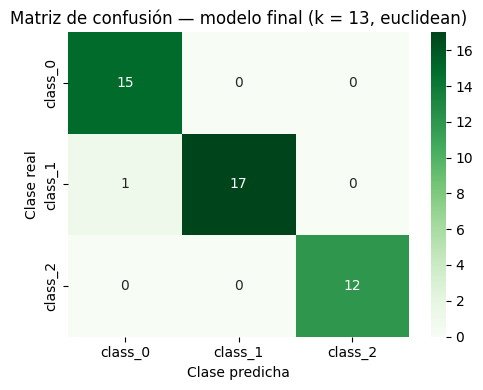

🔎 HALLAZGO: Accuracy en prueba = 0.978; estimación por validación cruzada = 0.970 ± 0.028. El resultado en prueba es consistente con la estimación (dentro de ± 2 desviaciones).


In [25]:
# ============================================
# 15. Modelo final con hiperparámetros seleccionados
# ============================================

# Parámetros de la métrica ganadora en la sección 14
params_finales = metricas[mejor_metrica]

# El pipeline recibe los datos SIN escalar: el StandardScaler va incluido
modelo_final = make_pipeline(StandardScaler(),
                             KNeighborsClassifier(n_neighbors=mejor_k, **params_finales))
modelo_final.fit(X_train, y_train)

# Única evaluación sobre el conjunto de prueba
y_pred_final = modelo_final.predict(X_test)
acc_final = accuracy_score(y_test, y_pred_final)

print(f"Modelo final: k = {mejor_k}, métrica = '{mejor_metrica}'")
print(f"Accuracy (prueba): {acc_final:.3f}")
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_final, target_names=nombres_clases))

cm_final = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Greens",
            xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title(f"Matriz de confusión — modelo final (k = {mejor_k}, {mejor_metrica})")
plt.tight_layout()
plt.show()

# --- Hallazgo: consistencia entre estimación CV y resultado en prueba ---
acc_cv_final = resultados_metricas.loc[mejor_metrica, "accuracy_media"]
desv_cv_final = resultados_metricas.loc[mejor_metrica, "desv"]
consistente = abs(acc_final - acc_cv_final) <= 2 * desv_cv_final

hallazgo(f"Accuracy en prueba = {acc_final:.3f}; estimación por validación cruzada = {acc_cv_final:.3f} ± {desv_cv_final:.3f}. "
         + ("El resultado en prueba es consistente con la estimación (dentro de ± 2 desviaciones)."
            if consistente else
            "El resultado en prueba se aleja de la estimación: con 45 observaciones, la partición puede estar influyendo."))

## 16. Conclusión

La conclusión se construye a partir de los resultados de todo el taller. Si alguna decisión cambia (semilla, rango de k, métricas evaluadas), el texto se actualiza solo y nunca contradice las tablas.

In [26]:
# ============================================
# 16. Conclusión dinámica del taller
# ============================================

print("=" * 70)
print("CONCLUSIONES DEL TALLER")
print("=" * 70)

print(f"\n1. Escalamiento: sin escalar, '{aporte.index[0]}' concentra el {aporte.iloc[0]:.1%} de la distancia. "
      f"Escalar lleva el accuracy medio (CV) de {m_sin:.3f} a {m_con:.3f}"
      f"{', una mejora concluyente' if escala_concluyente else ''}. "
      "En KNN, escalar no es opcional.")

print(f"\n2. Selección de k: el mejor valor por validación cruzada es k = {mejor_k} "
      f"({acc_mejor_k:.3f} ± {desv_mejor_k:.3f}). "
      + ("La curva es plana: la elección de k dentro del rango evaluado tiene poco impacto."
         if rango_acc < desv_tipica else
         "La elección de k tiene impacto real en el desempeño."))

print(f"\n3. Métrica de distancia: '{mejor_metrica}' obtiene el mayor accuracy medio; "
      + (f"su ventaja sobre '{segunda_metrica}' es concluyente."
         if metrica_concluyente else
         f"su ventaja sobre '{segunda_metrica}' no supera la variabilidad entre folds, por lo que no puede afirmarse que sea mejor.")
      + f" '{peor_metrica}' queda en último lugar.")

print(f"\n4. Evaluación final: el modelo (k = {mejor_k}, '{mejor_metrica}') alcanza {acc_final:.3f} en prueba, "
      f"frente a {acc_base:.3f} del modelo base (k = 5, euclidean). "
      f"Con {len(y_test)} observaciones de prueba, esa diferencia equivale a "
      f"{round(abs(acc_final - acc_base) * len(y_test))} clasificaciones.")

print(f"\n5. Método: k y métrica se eligieron solo con entrenamiento (validación cruzada repetida); "
      "el conjunto de prueba se usó una única vez para el modelo final.")

CONCLUSIONES DEL TALLER

1. Escalamiento: sin escalar, 'proline' concentra el 99.7% de la distancia. Escalar lleva el accuracy medio (CV) de 0.695 a 0.956, una mejora concluyente. En KNN, escalar no es opcional.

2. Selección de k: el mejor valor por validación cruzada es k = 13 (0.970 ± 0.028). La curva es plana: la elección de k dentro del rango evaluado tiene poco impacto.

3. Métrica de distancia: 'euclidean' obtiene el mayor accuracy medio; su ventaja sobre 'manhattan' no supera la variabilidad entre folds, por lo que no puede afirmarse que sea mejor. 'chebyshev' queda en último lugar.

4. Evaluación final: el modelo (k = 13, 'euclidean') alcanza 0.978 en prueba, frente a 0.933 del modelo base (k = 5, euclidean). Con 45 observaciones de prueba, esa diferencia equivale a 2 clasificaciones.

5. Método: k y métrica se eligieron solo con entrenamiento (validación cruzada repetida); el conjunto de prueba se usó una única vez para el modelo final.
